✅ No Data Leakage
 ✅ Proper EDA
 ✅ All Features Used
 ✅ Correlation Analysis
 ✅ Pipeline
 ✅ Cross Validation
 ✅ Hyperparameter Tuning
 ✅ Multiple Models Comparison
 ✅ Residual Analysis
 ✅ Feature Importance
 ✅ Final Model Selection

1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso
)

from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    AdaBoostRegressor
)

2. Load Dataset

In [2]:
df = pd.read_csv(r"C:\Users\Indresh Kumar\Downloads\headbrain.csv")

print(df.head())
print(df.shape)

   Gender  Age Range  Head Size(cm^3)  Brain Weight(grams)
0       1          1             4512                 1530
1       1          1             3738                 1297
2       1          1             4261                 1335
3       1          1             3777                 1282
4       1          1             4177                 1590
(237, 4)


3. Basic Information

In [3]:
print(df.info())

print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 237 entries, 0 to 236
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Gender               237 non-null    int64
 1   Age Range            237 non-null    int64
 2   Head Size(cm^3)      237 non-null    int64
 3   Brain Weight(grams)  237 non-null    int64
dtypes: int64(4)
memory usage: 7.5 KB
None
           Gender   Age Range  Head Size(cm^3)  Brain Weight(grams)
count  237.000000  237.000000       237.000000           237.000000
mean     1.434599    1.535865      3633.991561          1282.873418
std      0.496753    0.499768       365.261422           120.340446
min      1.000000    1.000000      2720.000000           955.000000
25%      1.000000    1.000000      3389.000000          1207.000000
50%      1.000000    2.000000      3614.000000          1280.000000
75%      2.000000    2.000000      3876.000000          1350.000000
max      2.000000    2.000000   

4. Missing Values

Gender                 0
Age Range              0
Head Size(cm^3)        0
Brain Weight(grams)    0
dtype: int64


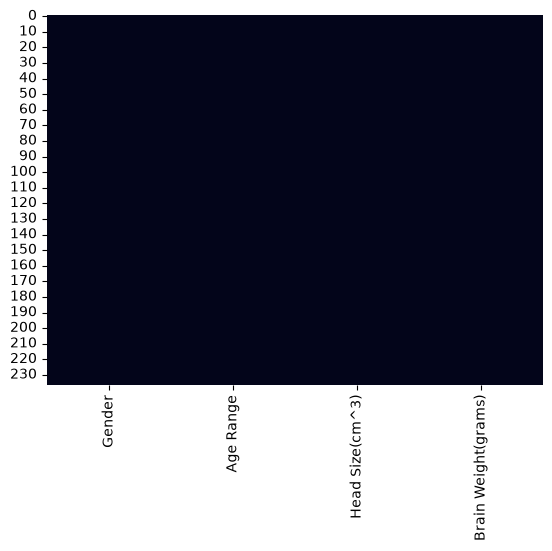

In [4]:
print(df.isnull().sum())

sns.heatmap(df.isnull(),cbar=False)
plt.show()

5. Correlation Analysis

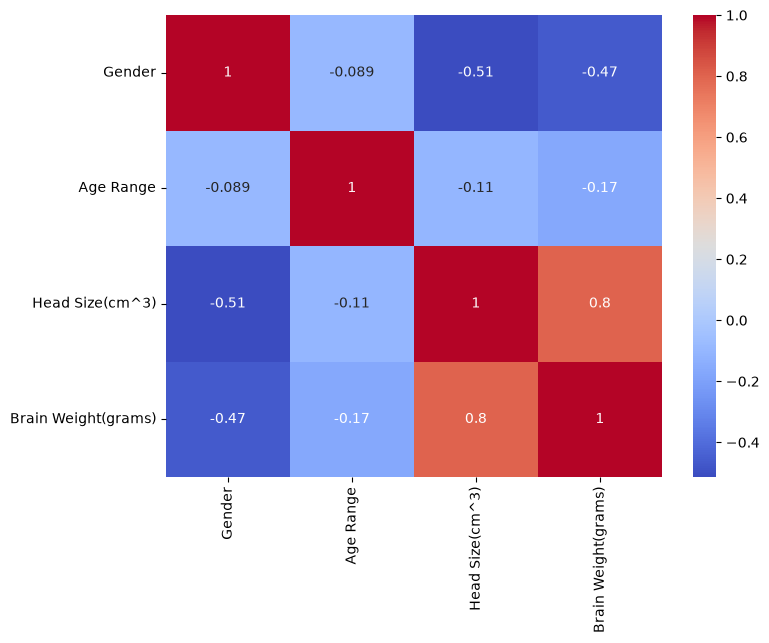

In [5]:
plt.figure(figsize=(8,6))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm'
)

plt.show()

6. Distribution Plots

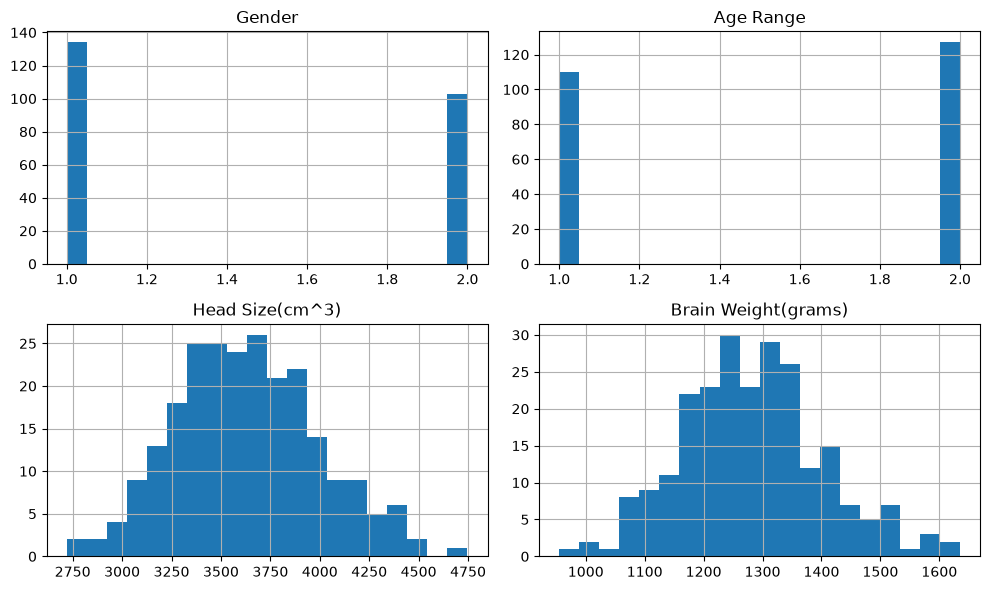

In [6]:
df.hist(
    figsize=(10,6),
    bins=20
)

plt.tight_layout()
plt.show()

7. Pairplot

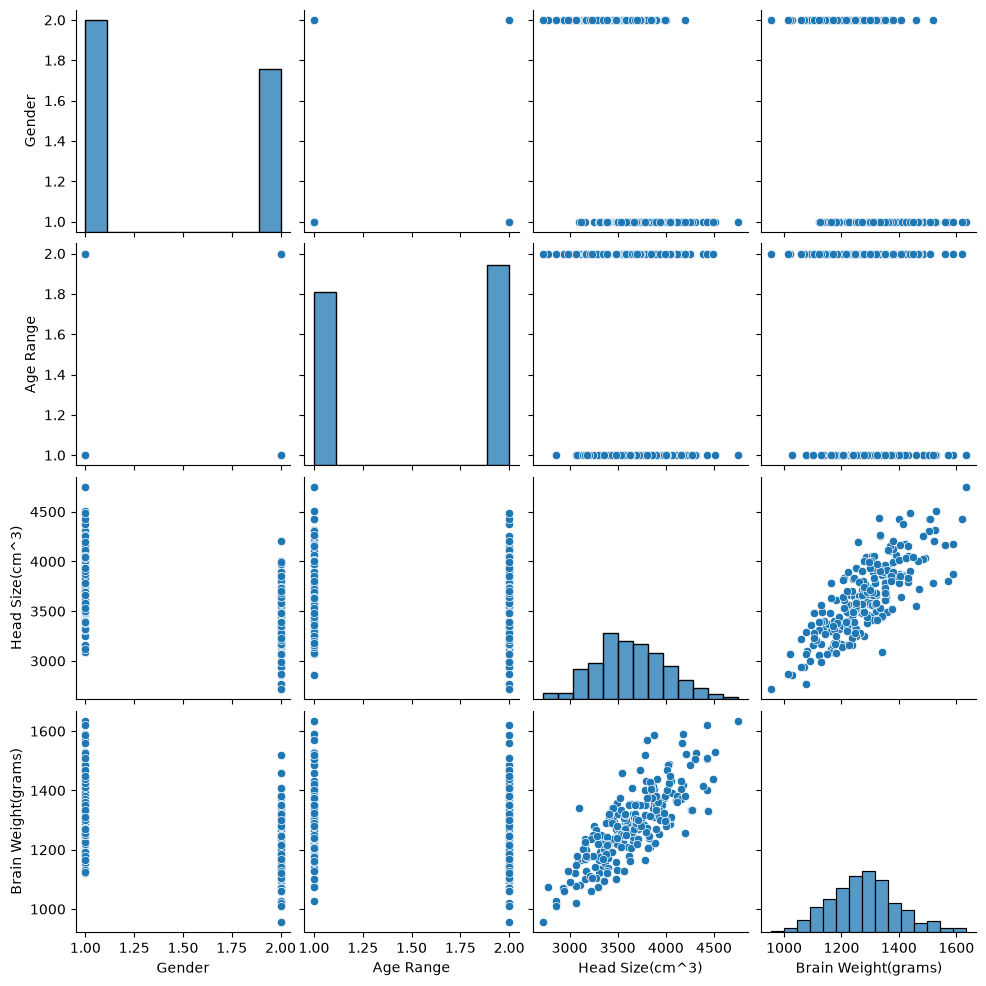

In [7]:
sns.pairplot(df)

plt.show()

8. Boxplots For Outliers

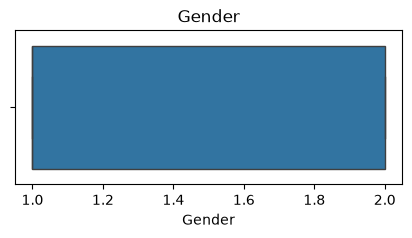

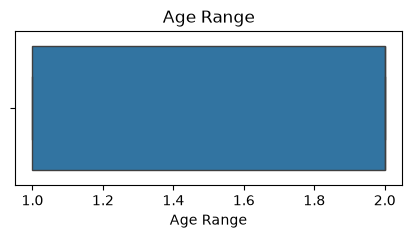

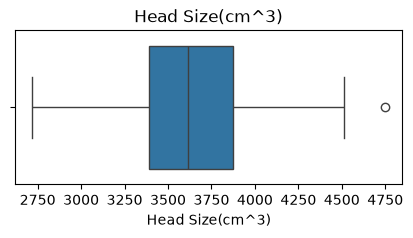

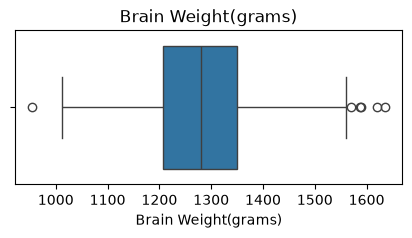

In [8]:
for col in df.columns:
    
    plt.figure(figsize=(5,2))
    
    sns.boxplot(
        x=df[col]
    )
    
    plt.title(col)

    plt.show()

9. Feature & Target Selection

Earlier project mistake:

❌ Only Head Size used

Now:

✅ All Features

In [9]:
X = df.drop(
    "Brain Weight(grams)",
    axis=1
)

y = df["Brain Weight(grams)"]

10. Train Test Split

Before scaling.

In [10]:
X_train , X_test , y_train , y_test = train_test_split(
    
    X,
    y,
    
    test_size=0.20,
    
    random_state=42
)

11. Model Dictionary

In [11]:
models = {

    "Linear Regression":LinearRegression(),

    "Ridge":Ridge(),

    "Lasso":Lasso(),

    "KNN":KNeighborsRegressor(),

    "SVR":SVR(),

    "Decision Tree":DecisionTreeRegressor(),

    "Random Forest":RandomForestRegressor(),

    "Gradient Boosting":GradientBoostingRegressor(),

    "AdaBoost":AdaBoostRegressor()
}

12. Cross Validation Comparison

In [12]:
results = []

for name,model in models.items():

    pipe = Pipeline([
        
        ('scaler',StandardScaler()),
        
        ('model',model)
    ])

    score = cross_val_score(
        pipe,
        X,
        y,
        cv=5,
        scoring='r2'
    )

    results.append([
        name,
        score.mean(),
        score.std()
    ])

13. Model Comparison Table

In [13]:
result_df = pd.DataFrame(

    results,

    columns=[
        'Model',
        'Mean_R2',
        'STD'
    ]
)

result_df.sort_values(
    by='Mean_R2',
    ascending=False,
    inplace=True
)

print(result_df)

               Model   Mean_R2       STD
1              Ridge  0.505797  0.118292
0  Linear Regression  0.505591  0.118971
2              Lasso  0.502036  0.128547
8           AdaBoost  0.401847  0.225621
7  Gradient Boosting  0.362731  0.145877
6      Random Forest  0.342586  0.186835
3                KNN  0.255286  0.240358
5      Decision Tree -0.107763  0.361083
4                SVR -0.359994  0.503698


14. Hyperparameter Tuning

Random Forest Example

In [14]:
rf = RandomForestRegressor(
    random_state=42
)

params = {

    'n_estimators':[50,100,200],

    'max_depth':[2,3,5,10],

    'min_samples_split':[2,5,10]
}

grid = GridSearchCV(

    rf,

    params,

    cv=5,

    scoring='r2'
)

grid.fit(
    X_train,
    y_train
)

print(grid.best_params_)

{'max_depth': 3, 'min_samples_split': 10, 'n_estimators': 100}


15. Train Best Model

In [15]:
best_model = grid.best_estimator_

best_model.fit(
    X_train,
    y_train
)

pred = best_model.predict(
    X_test
)

16. Metrics

In [16]:
mae = mean_absolute_error(
    y_test,
    pred
)

mse = mean_squared_error(
    y_test,
    pred
)

rmse = np.sqrt(mse)

r2 = r2_score(
    y_test,
    pred
)

print("MAE :",mae)

print("MSE :",mse)

print("RMSE :",rmse)

print("R2 :",r2)


MAE : 56.82959553747943
MSE : 5371.214400793041
RMSE : 73.28856937335482
R2 : 0.6722541819380076


17. Residual Analysis

Very Important Interview Topic

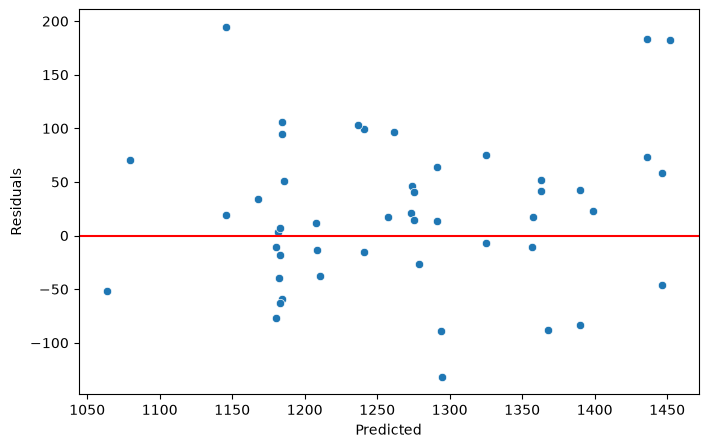

In [17]:
residuals = y_test - pred

plt.figure(figsize=(8,5))

sns.scatterplot(
    
    x=pred,
    
    y=residuals
)

plt.axhline(
    y=0,
    color='red'
)

plt.xlabel("Predicted")

plt.ylabel("Residuals")

plt.show()

18. Actual vs Predicted

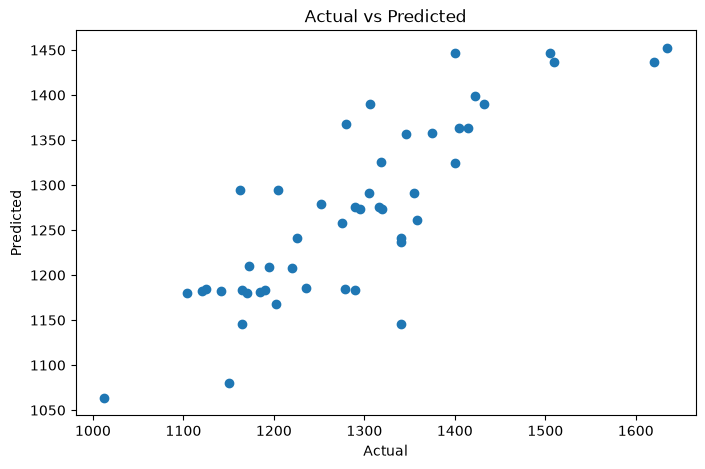

In [18]:
plt.figure(figsize=(8,5))

plt.scatter(
    
    y_test,
    
    pred
)

plt.xlabel("Actual")

plt.ylabel("Predicted")

plt.title(
    "Actual vs Predicted"
)

plt.show()

19. Feature Importance

For Tree Models

In [19]:
importance = pd.DataFrame({

    'Feature':X.columns,

    'Importance':
    best_model.feature_importances_
})

importance.sort_values(

    by='Importance',

    ascending=False,

    inplace=True
)

print(importance)

           Feature  Importance
2  Head Size(cm^3)    0.992703
1        Age Range    0.005078
0           Gender    0.002219


20. Business Conclusion

Notebook के अंत में:

1. Head Size is the strongest predictor.

2. Gender contributes moderately.

3. Age Range contributes less.

4. Random Forest achieved the best cross validated performance.

5. Model can estimate brain weight with acceptable error.

6. Pipeline prevents data leakage.

7. Cross Validation confirms model stability.

I built an end-to-end regression project to predict brain weight using demographic and physiological variables. I performed EDA, outlier analysis, feature engineering, model comparison using 9 regression algorithms, hyperparameter tuning with GridSearchCV, 5-fold cross-validation, residual analysis, feature importance analysis, and selected the final model based on generalized performance rather than a single train-test split